# Verification — Lang et al. (2024) fused cell-cycle model at the authors' fitted parameters

This notebook verifies `cell_cycle_oscillator_lang2024_fitted.bngl` against the authors' own
release of the model. That release is `paulflang/cell_cycle_petab` at commit
`362b6667a2096b6c1cab43ddc3a92d4174c5a087`, `versions/v3.2.0/` (MIT licence). The other
notebook in this folder, `verify_lang2024.ipynb`, is the entry point and covers the four
Fig 1 submodels; this one covers the `_fitted` file only.

The `_fitted` file is generated by `generator/build_lang2024_fitted.py`. It takes the
reaction network of `cell_cycle_oscillator_lang2024_fused.bngl` and the numbers in the
authors' tables, as follows:

* **Parameters.** All 205 values come from `results_20220421/parameters_v3.2.0_optimized.tsv`.
  This is the table the authors simulated to produce `results_20220421/optimisation.tsv`,
  the model curves of their v3.2.0 fit figure (Fig L in S1 Appendix of Lang et al. (2024);
  "Supplementary Figure 12" in the repository README).
* **Initial state.** It is the PEtab `wt` condition (`experimentalCondition_v3.2.0.tsv`).

What is checked, and against what:

| | check | reference | tolerance |
|---|---|---|---|
| (a) | each of the 205 parameter values, and the `ic_wt_cell__*` parameter assigned to each of the 73 species | optimized table; PEtab `wt` condition | exact (same double) |
| (b) | species, reactions, rate laws | `_fused` and the authors' `cell_cycle_v3.2.0.bngl` (both generated by BNG 2.9.3), and the authors' SBML | identical |
| L1 | BioNetGen CVODE output (`.gdat`, `.cdat`) of this file's own protocol | independent SciPy integration of the generated `.net` | max rel err 1e-5 |
| (c) L2 | the eight observation functions, from this file's network | the authors' AMICI simulation output, 8 x 600 points | max rel err 5e-5 |
| (d) | species trajectories and the PEtab observables | an ODE built directly from the authors' SBML kinetic laws, with the PEtab tables applied | 1e-8 vs this file's network; 5e-5 vs AMICI |

**How to run.** Set `BNGPATH` to a BioNetGen 2.9.3 directory and run from this folder.
Everything else is committed: the upstream files are vendored under `reference/` and checked
against their sha256. Network generation needs only Perl. The `simulate` protocol also needs
BioNetGen's `run_network` binary to launch, and on Linux that requires glibc 2.34 or later.
Where it cannot launch, the notebook says so, skips the fresh simulation, and checks the
committed `reference/` outputs instead.

The committed outputs and reference files were produced on a RHEL 8 host (glibc 2.28). There
the stock `run_network` binary was launched unchanged under a glibc 2.34 loader.

**Plot convention:** lines = BioNetGen; open markers = the reference named in each panel.

In [1]:
import ast, csv, hashlib, itertools, operator, os, re, subprocess, sys, tempfile, time
import xml.etree.ElementTree as ET
from collections import Counter, defaultdict
from pathlib import Path

import numpy as np
import pandas as pd
import yaml
import matplotlib
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.sparse import csc_matrix, csr_matrix

STEM = "cell_cycle_oscillator_lang2024_fitted"
FUSED_STEM = "cell_cycle_oscillator_lang2024_fused"


def find_model_dir():
    for c in (Path.cwd(), Path.cwd() / "models" / "cell_cycle_oscillator_lang2024"):
        if (c / f"{STEM}.bngl").exists():
            return c.resolve()
    raise FileNotFoundError("run this notebook from models/cell_cycle_oscillator_lang2024/")


MODEL_DIR = find_model_dir()
os.chdir(MODEL_DIR)
REF = Path("reference")
sys.path.insert(0, "generator")
sys.path.insert(0, "../../skills/curate-model/scripts")
import build_lang2024_fitted as gen                      # pins, protocol constants, generator
from verification_figure import Comparison, summarize, verdict_footer

BNG2 = Path(os.path.expanduser(os.environ.get("BNGPATH", "~/Simulations/BioNetGen-2.9.3"))) / "BNG2.pl"
assert BNG2.is_file(), "set BNGPATH to a BioNetGen 2.9.3 directory"

# Tolerances (asserted below; the reasons are given where each one is used).
TOL_SOLVER = 1e-8   # SciPy reference: Radau rtol 1e-10 vs 1e-12
TOL_BNG = 1e-5      # L1: BNG CVODE (rtol 1e-10, atol 1e-12) vs SciPy
TOL_AMICI = 5e-5    # L2: vs the authors' AMICI output
TOL_SBML = 1e-8     # (d): SBML-built ODE vs this file's network (same ODE; roundoff only)
FLOOR = 1e-12       # AU; relative-error denominator floor (two species are identically 0)
RTOL_REF, ATOL_REF = 1e-10, 1e-14   # SciPy reference integration

## Pinned inputs

Every upstream file in `reference/` must have the bytes that were pinned. So must the
`_fused` file whose body the generator copies. The generator must also reproduce the
committed `_fitted` file byte for byte, which shows that no number in it was typed by hand.

In [2]:
def sha256(p):
    return hashlib.sha256(Path(p).read_bytes()).hexdigest()


print(f"upstream: {gen.UPSTREAM_REPO} @ {gen.UPSTREAM_COMMIT}")
for name, (upath, digest) in gen.PINS.items():
    got = sha256(REF / name)
    assert got == digest, f"{name}: sha256 {got} != pinned {digest}"
    print(f"  ok  {upath:<62s} {digest[:16]}  -> reference/{name}")
assert sha256(f"{FUSED_STEM}.bngl") == gen.FUSED_SHA256
print(f"  ok  {FUSED_STEM}.bngl (model-body template) {gen.FUSED_SHA256[:16]}")

fitted_text = Path(f"{STEM}.bngl").read_text()
assert gen.build() == fitted_text, "generator output differs from the committed .bngl"
FITTED_SHA = sha256(f"{STEM}.bngl")
print(f"\n{STEM}.bngl is reproduced byte for byte by the generator; sha256 {FITTED_SHA}")

upstream: https://github.com/paulflang/cell_cycle_petab @ 362b6667a2096b6c1cab43ddc3a92d4174c5a087
  ok  LICENCE                                                        d2d58b863fb4b29b  -> reference/lang2024_upstream_LICENCE
  ok  versions/v3.2.0/cell_cycle_v3.2.0.bngl                         0f23b3e866aff406  -> reference/lang2024_upstream_cell_cycle_v3.2.0.bngl
  ok  versions/v3.2.0/cell_cycle_v3.2.0_sbml.xml                     5ac5ea95131f7b57  -> reference/lang2024_upstream_cell_cycle_v3.2.0_sbml.xml
  ok  versions/v3.2.0/cell_cycle_v3.2.0_petab.xml                    f8a15a57f71d334f  -> reference/lang2024_upstream_cell_cycle_v3.2.0_petab.xml
  ok  versions/v3.2.0/parameters_v3.2.0.tsv                          a0d2cb24f0a16138  -> reference/lang2024_upstream_parameters_v3.2.0.tsv
  ok  versions/v3.2.0/experimentalCondition_v3.2.0.tsv               28c13f5038df7c41  -> reference/lang2024_upstream_experimentalCondition_v3.2.0.tsv
  ok  versions/v3.2.0/observables_v3.2.0.tsv        

## Helpers

The `.net` reader and the mass-action right-hand side follow the house helpers, e.g. in
`verify_kocieniewski2012.ipynb`. The order-invariant species canonicalization follows
`compare_network_imoto2026.py`. The SBML reader is written here from scratch, using
`xml.etree` and no SBML library or BioNetGen code. It accepts only kinetic laws that are
pure products, and raises on anything else. Arithmetic in model files is evaluated by a
restricted AST walker (numbers, names, + - * / ^), never by `eval`.

In [3]:
_OPS = {ast.Add: operator.add, ast.Sub: operator.sub, ast.Mult: operator.mul,
        ast.Div: operator.truediv, ast.Pow: operator.pow}


def safe_eval(expr, names):
    def ev(n):
        if isinstance(n, ast.Expression):
            return ev(n.body)
        if isinstance(n, ast.Constant) and isinstance(n.value, (int, float)):
            return float(n.value)
        if isinstance(n, ast.Name):
            return names[n.id]
        if isinstance(n, ast.BinOp) and type(n.op) in _OPS:
            return _OPS[type(n.op)](ev(n.left), ev(n.right))
        if isinstance(n, ast.UnaryOp) and isinstance(n.op, (ast.USub, ast.UAdd)):
            return -ev(n.operand) if isinstance(n.op, ast.USub) else ev(n.operand)
        raise ValueError(f"unsupported expression {expr!r}")
    return ev(ast.parse(expr.replace("^", "**"), mode="eval"))


def bngl_block(text, name):
    m = re.search(rf"^\s*begin {name}\s*$(.*?)^\s*end {name}\s*$", text, re.S | re.M)
    return [ln.split("#", 1)[0].strip() for ln in m.group(1).splitlines()
            if ln.split("#", 1)[0].strip()]


def bngl_parameters(text):
    out = {}
    for ln in bngl_block(text, "parameters"):
        name, expr = ln.split(None, 1)
        out[name] = float(safe_eval(expr.replace(" ", ""), out))
    return out


def bngl_seeds(text):
    return [tuple(ln.rsplit(None, 1)) for ln in bngl_block(text, "seed species")]


ALLOWED_ACTIONS = re.compile(r"^(generate_network|writeSBML|simulate)\(")


def netgen_copy(text, label):
    # Model block verbatim; the actions are replaced by generate_network alone. The source
    # actions are checked against a whitelist first, since BNG2.pl executes actions.
    head, sep, tail = text.rpartition("end model")
    assert sep and "begin actions" not in head, label
    for ln in tail.replace("\\\n", " ").splitlines():
        c = ln.split("#", 1)[0].strip()
        if c and c not in ("begin actions", "end actions"):
            assert ALLOWED_ACTIONS.match(c), f"{label}: unexpected action {c!r}"
    return head + sep + "\n\nbegin actions\n  generate_network({overwrite=>1})\nend actions\n"


def run_bng(text, stem, workdir):
    path = Path(workdir) / f"{stem}.bngl"
    path.write_text(text)
    r = subprocess.run(["perl", str(BNG2), "--outdir", str(workdir), str(path)],
                       capture_output=True, text=True, timeout=900)
    return r, Path(workdir)


def read_net(path):
    blocks, block = defaultdict(list), None
    for raw in Path(path).read_text().splitlines():
        line = raw.strip()
        if not line or line.startswith("#"):
            continue
        if line.startswith("begin "):
            block = line[6:].strip(); continue
        if line.startswith("end "):
            block = None; continue
        body, _, comment = line.partition("#")
        blocks[block].append((body.split(), comment.strip()))
    net = dict(
        params=[(f[1], "".join(f[2:])) for f, _ in blocks["parameters"]],
        species=[(f[1], "".join(f[2:])) for f, _ in blocks["species"]],
        reactions=[([int(x) - 1 for x in f[1].split(",") if x != "0"],
                    [int(x) - 1 for x in f[2].split(",") if x != "0"], "".join(f[3:]))
                   for f, _ in blocks["reactions"]],
        groups=[(f[1], [(int(t.rpartition("*")[2]) - 1,
                         float(t.rpartition("*")[0]) if "*" in t else 1.0)
                        for t in (f[2].split(",") if len(f) > 2 else [])])
                for f, _ in blocks["groups"]],
        functions=[(f[1].replace("()", ""), "".join(f[2:])) for f, _ in blocks["functions"]],
    )
    return net


def net_structure(path):
    # A .net with comments and whitespace removed, for the exact structural comparison.
    return [" ".join(ln.split("#", 1)[0].split()) for ln in Path(path).read_text().splitlines()
            if ln.split("#", 1)[0].strip()]


def net_values(net, overrides=None):
    pv = {}
    for name, expr in net["params"]:
        pv[name] = float(overrides[name]) if overrides and name in overrides else safe_eval(expr, pv)
    y0 = np.array([safe_eval(e, pv) for _, e in net["species"]])
    k = np.array([safe_eval(e, pv) for _, _, e in net["reactions"]])
    return pv, y0, k


# ----- order-invariant species canonicalization (after compare_network_imoto2026.py) -----
def _split_top(s, sep):
    out, depth, cur = [], 0, ""
    for ch in s:
        depth += (ch == "(") - (ch == ")")
        if ch == sep and depth == 0:
            out.append(cur); cur = ""
        else:
            cur += ch
    return out + [cur]


def canonical(text):
    mols = []
    for part in _split_top(re.sub(r"^@\w+::?", "", text.strip()), "."):
        m = re.match(r"^(\w+)\((.*)\)$", re.sub(r"@\w+", "", part.strip()))
        sites = {}
        for tok in filter(None, (t.strip() for t in m.group(2).split(","))):
            sm = re.match(r"^(\w+)(~\w+)?(!\w+)?$", tok)
            sites[sm.group(1)] = (sm.group(2)[1:] if sm.group(2) else None,
                                  sm.group(3)[1:] if sm.group(3) else None)
        mols.append((m.group(1), sites))

    def render(order):
        bonds = {}
        for i in order:
            for s in sorted(mols[i][1]):
                b = mols[i][1][s][1]
                if b and b not in bonds:
                    bonds[b] = len(bonds) + 1
        return ".".join(
            f"{mols[i][0]}(" + ",".join(
                s + (f"~{st}" if st else "") + (f"!{bonds[b]}" if b else "")
                for s, (st, b) in sorted(mols[i][1].items())) + ")" for i in order)

    local = [(n, tuple(sorted((s, v[0], v[1] is not None) for s, v in st.items())))
             for n, st in mols]
    groups = defaultdict(list)
    for i, key in enumerate(local):
        groups[key].append(i)
    blocks = [groups[k] for k in sorted(groups)]
    return min(render([i for b in combo for i in b])
               for combo in itertools.product(*(itertools.permutations(b) for b in blocks)))


# ----- SBML (level 2 version 3, as written by BioNetGen's writeSBML) -----
SB, MM = "{http://www.sbml.org/sbml/level2/version3}", "{http://www.w3.org/1998/Math/MathML}"


def read_sbml(path):
    model = ET.parse(path).getroot().find(f"{SB}model")
    out = dict(
        comps={c.get("id"): float(c.get("size")) for c in model.iter(f"{SB}compartment")},
        species=[dict(id=s.get("id"), name=s.get("name"), comp=s.get("compartment"),
                      ic=float(s.get("initialConcentration")))
                 for s in model.find(f"{SB}listOfSpecies")],
        params={p.get("id"): float(p.get("value")) for p in model.find(f"{SB}listOfParameters")
                if p.get("value") is not None},
        reactions=[])
    for r in model.find(f"{SB}listOfReactions"):
        assert r.get("reversible") == "false"
        def refs(tag):
            lst = r.find(f"{SB}{tag}")
            return [x.get("species") for x in ([] if lst is None else lst)
                    for _ in range(int(float(x.get("stoichiometry", "1"))))]
        out["reactions"].append(dict(reactants=refs("listOfReactants"),
                                     products=refs("listOfProducts"),
                                     law=r.find(f"{SB}kineticLaw/{MM}math")[0]))
    return out


def monomial(node):
    # A kinetic law that is a pure product -> (numeric factor, [symbols]); raises otherwise.
    tag = node.tag.replace(MM, "")
    if tag == "ci":
        return 1.0, [node.text.strip()]
    if tag == "cn":
        return float(node.text), []
    if tag == "apply" and node[0].tag == f"{MM}times":
        c, syms = 1.0, []
        for ch in node[1:]:
            cc, ss = monomial(ch)
            c, syms = c * cc, syms + ss
        return c, syms
    raise ValueError(f"kinetic law is not a mass-action product: <{tag}>")


# ----- mass-action ODE, from either source -----
def massaction(k, reactants, products, n, y0, inv_volume=None):
    m = len(k)
    ra = np.array([r[0] if r else -1 for r in reactants])
    rb = np.array([r[1] if len(r) > 1 else -1 for r in reactants])
    assert all(len(r) <= 2 for r in reactants)
    rows, cols, vals = [], [], []
    for j, (rs, ps) in enumerate(zip(reactants, products)):
        c = Counter()
        for i in rs:
            c[i] -= 1
        for i in ps:
            c[i] += 1
        for i, v in c.items():
            if v:
                rows.append(i); cols.append(j); vals.append(v)
    S = csr_matrix((vals, (rows, cols)), shape=(n, m))
    if inv_volume is not None:
        S = csr_matrix(S.multiply(np.asarray(inv_volume)[:, None]))
    has_a, has_b = ra >= 0, rb >= 0
    ra0, rb0 = np.where(has_a, ra, 0), np.where(has_b, rb, 0)
    jr = np.r_[np.nonzero(has_a)[0], np.nonzero(has_b)[0]]
    jc = np.r_[ra[has_a], rb[has_b]]

    def flux(y):
        f = k.copy()
        f[has_a] *= y[ra0[has_a]]
        f[has_b] *= y[rb0[has_b]]
        return f

    def rhs(t, y):
        return S @ flux(y)

    def jac(t, y):
        da = k[has_a] * np.where(has_b[has_a], y[rb0[has_a]], 1.0)
        db = k[has_b] * y[ra0[has_b]]
        return (S @ csr_matrix((np.r_[da, db], (jr, jc)), shape=(m, n))).toarray()

    return dict(rhs=rhs, jac=jac, y0=np.asarray(y0, float))


def net_ode(net, overrides=None):
    pv, y0, k = net_values(net, overrides)
    sysd = massaction(k, [r for r, _, _ in net["reactions"]], [p for _, p, _ in net["reactions"]],
                      len(y0), y0)
    sysd["pv"] = pv
    return sysd


def integrate(sysd, t, rtol=RTOL_REF, atol=ATOL_REF):
    sol = solve_ivp(sysd["rhs"], (t[0], t[-1]), sysd["y0"], method="Radau", t_eval=t,
                    rtol=rtol, atol=atol, jac=sysd["jac"])
    assert sol.success, sol.message
    return sol.y


def rel_err(a, b, floor=FLOOR):
    a, b = np.asarray(a, float), np.asarray(b, float)
    return np.abs(a - b) / np.maximum(np.abs(b), floor)


def functions_of(net, y, pv):
    # The .net's observation functions, evaluated on species trajectories y (n x T).
    names = dict(pv)
    names.update({g: sum(w * y[i] for i, w in members) for g, members in net["groups"]})
    return {f: safe_eval(e, names) for f, e in net["functions"]}

## (a) Parameters and initial conditions equal the authors' fitted table and wt condition

The authors' file `results_20220421/v3.2.0_plot.yaml` defines the PEtab problem whose
simulation produced `optimisation.tsv`. The cell below first checks that it names the
optimized table, the `wt` condition table, the observables table and `cell_cycle_v3.2.0_petab.xml`.
Then, for every parameter, the value in the `_fitted` file must be the same double as the
table's `nominalValue`. PEtab gives `nominalValue` on the linear scale whatever
`parameterScale` says.

For the initial state, each species is followed through three files:

1. Its BioNetGen string is read from `cell_cycle_v3.2.0_sbml.xml`.
2. Its PEtab id is taken from `cell_cycle_v3.2.0_petab.xml`. That file is the same SBML,
   species for species, with the ids renamed; the cell checks this too.
3. Its `wt` cell is read from the condition table.

The `ic_wt_cell__*` parameter named in that cell must be the one that seeds the species in
the `_fitted` file.

In [4]:
def table(name):
    return pd.read_csv(REF / name, sep="\t", dtype=str).set_index("parameterId")


opt = table("lang2024_upstream_results_20220421_parameters_v3.2.0_optimized.tsv")
nom = table("lang2024_upstream_parameters_v3.2.0.tsv")
cond = pd.read_csv(REF / "lang2024_upstream_experimentalCondition_v3.2.0.tsv", sep="\t",
                   dtype=str).set_index("conditionId")
obs_tab = pd.read_csv(REF / "lang2024_upstream_observables_v3.2.0.tsv", sep="\t", dtype=str)
plot_yaml = yaml.safe_load((REF / "lang2024_upstream_results_20220421_v3.2.0_plot.yaml").read_text())
prob = plot_yaml["problems"][0]
assert plot_yaml["parameter_file"] == "parameters_v3.2.0_optimized.tsv"
assert prob["sbml_files"] == ["../cell_cycle_v3.2.0_petab.xml"]
assert prob["condition_files"] == ["../experimentalCondition_v3.2.0.tsv"]
assert prob["observable_files"] == ["../observables_v3.2.0.tsv"]
assert list(cond.index) == ["wt"]
print("v3.2.0_plot.yaml: optimized table + petab.xml + wt condition + observables table  ok")

fitted_params = bngl_parameters(fitted_text)
fused_text = Path(f"{FUSED_STEM}.bngl").read_text()
fused_params = bngl_parameters(fused_text)
assert set(fitted_params) == set(opt.index) and len(fitted_params) == len(opt) == 205
mismatch = [k for k in opt.index if fitted_params[k] != float(opt.loc[k, "nominalValue"])]
assert not mismatch, mismatch
n_est = int((opt["estimate"] == "1").sum())
print(f"parameters: {len(opt)}/{len(opt)} equal the optimized table's nominalValue exactly "
      f"({n_est} estimated, {len(opt) - n_est} fixed)")

# The 28 fixed values are the same in the nominal and the optimized table, so the wt initial
# state of the fixed species does not depend on which table one reads.
fixed = opt.index[opt["estimate"] == "0"]
assert all(float(opt.loc[k, "nominalValue"]) == float(nom.loc[k, "nominalValue"]) for k in fixed)
print(f"fixed parameters: {len(fixed)} identical in the nominal and the optimized table")

# species -> BNG string (sbml.xml) -> PEtab id (petab.xml) -> wt cell -> ic parameter
sbml = read_sbml(REF / "lang2024_upstream_cell_cycle_v3.2.0_sbml.xml")
petab = read_sbml(REF / "lang2024_upstream_cell_cycle_v3.2.0_petab.xml")
idmap = {a["id"]: b["id"] for a, b in zip(sbml["species"], petab["species"])}
assert len(idmap) == len(petab["species"]) == 73
assert [(s["comp"], s["ic"]) for s in sbml["species"]] == [(s["comp"], s["ic"]) for s in petab["species"]]
assert sbml["params"] == petab["params"] and sbml["comps"] == petab["comps"]
def law_txt(law, m):
    # MathML of a kinetic law, with each <ci> symbol renamed through m (unchanged if absent)
    return re.sub(r"<(\w+:)?ci>\s*(\S+)\s*</(\w+:)?ci>",
                  lambda mo: f"<ci>{m.get(mo.group(2), mo.group(2))}</ci>", ET.tostring(law).decode())


assert len(sbml["reactions"]) == len(petab["reactions"]) == 332
for ra, rb in zip(sbml["reactions"], petab["reactions"]):
    assert [idmap[x] for x in ra["reactants"]] == rb["reactants"]
    assert [idmap[x] for x in ra["products"]] == rb["products"]
    assert law_txt(ra["law"], idmap) == law_txt(rb["law"], {})
print("cell_cycle_v3.2.0_petab.xml == cell_cycle_v3.2.0_sbml.xml with species ids renamed  ok")

wt = cond.loc["wt"]
assert list(wt.index) == [s["id"] for s in petab["species"]]
seed_param = {canonical(p): e for p, e in bngl_seeds(fitted_text)}
sbml_canon = [canonical(s["name"]) for s in sbml["species"]]
assert set(seed_param) == set(sbml_canon) and len(seed_param) == 73
for c, s in zip(sbml_canon, petab["species"]):
    assert seed_param[c] == wt[s["id"]], (c, seed_param[c], wt[s["id"]])
print("initial state: all 73 species seeded by the ic_wt_cell__* parameter the wt condition "
      "assigns them, at the optimized table's value  ok")

# How the fitted file differs from _fused (by design)
changed = [k for k in opt.index if fitted_params[k] != fused_params[k]]
print(f"\nvs {FUSED_STEM}.bngl: {len(changed)} of 205 values differ (that file carries the "
      "pre-fit PEtab nominals). The fixed promoter values, where _fused follows the authors' "
      ".bngl seeds instead of the PEtab wt condition:")
def sig_digits(s):
    m = re.match(r"^[+-]?(\d*)\.?(\d*)", s.strip())
    return max(len((m.group(1) + m.group(2)).lstrip("0")), 1)


promoters = [k for k in fixed if k.startswith("ic_") and fitted_params[k] != fused_params[k]]
material = []
for k in promoters:
    shown = opt.loc[k, "nominalValue"]
    rounding = float(f"{fused_params[k]:.{sig_digits(shown)}g}") == float(shown)
    material += [] if rounding else [k]
    note = "  (the table's rounding of the _fused value)" if rounding else ""
    print(f"   {k[12:]:<46s} wt {fitted_params[k]:<8.3g} _fused {fused_params[k]:<11.6g}{note}")
assert len(promoters) == 14 and len(material) == 13

v3.2.0_plot.yaml: optimized table + petab.xml + wt condition + observables table  ok
parameters: 205/205 equal the optimized table's nominalValue exactly (177 estimated, 28 fixed)
fixed parameters: 28 identical in the nominal and the optimized table
cell_cycle_v3.2.0_petab.xml == cell_cycle_v3.2.0_sbml.xml with species ids renamed  ok
initial state: all 73 species seeded by the ic_wt_cell__* parameter the wt condition assigns them, at the optimized table's value  ok

vs cell_cycle_oscillator_lang2024_fused.bngl: 187 of 205 values differ (that file carries the pre-fit PEtab nominals). The fixed promoter values, where _fused follows the authors' .bngl seeds instead of the PEtab wt condition:
   CCNB_promoter_FOXM1_1__FOXM1_DBD_1_Thr600p_    wt 1.9e-07  _fused 1.90326e-07  (the table's rounding of the _fused value)
   CCNB_promoter_FOXM1_                           wt 0.0001   _fused 9.98097e-05
   CDC20_promoter_FOXM1_                          wt 0.0001   _fused 9.99238e-05
   CDC20_promo

## (b) The network is the authors' network

BioNetGen 2.9.3 generates three networks, with each file's actions replaced by
`generate_network` alone: `_fitted`, `_fused` and the authors' `cell_cycle_v3.2.0.bngl`. A
fourth run executes the `_fitted` file's own protocol unchanged, to produce the BioNetGen
simulation output used in L1.

Species are compared in a canonical form that does not depend on molecule order or bond
numbering. Reactions are compared as multisets of (reactants, products, rate-law
expression). The rate constants are compared against the authors' SBML in two steps. First,
each kinetic law is evaluated with the PEtab parameter table applied. Then the results are
matched, by reaction, against the numeric rate constants of the `_fitted` network.

In [5]:
WORK = Path(tempfile.mkdtemp(prefix="lang2024_fitted_"))
nets, logs = {}, {}
for stem, text in [(STEM, fitted_text), (FUSED_STEM, fused_text),
                   ("authors_v3.2.0", (REF / "lang2024_upstream_cell_cycle_v3.2.0.bngl").read_text())]:
    wd = WORK / f"netgen_{stem}"; wd.mkdir()
    r, _ = run_bng(netgen_copy(text, stem), stem, wd)
    assert r.returncode == 0, r.stdout[-3000:]
    assert "BioNetGen version 2.9.3" in r.stdout
    nets[stem] = read_net(wd / f"{stem}.net")
print("BioNetGen version 2.9.3: networks generated for", ", ".join(nets))

# The file's own protocol, unchanged (generate_network + simulate). This needs run_network.
full = WORK / "protocol"; full.mkdir()
r, _ = run_bng(fitted_text, STEM, full)
FRESH = (full / f"{STEM}_ode.gdat").exists()
if FRESH:
    assert r.returncode == 0, r.stdout[-3000:]
    print("protocol run: generate_network + simulate completed (run_network launched)")
else:
    assert (full / f"{STEM}.net").exists(), r.stdout[-3000:]
    print("protocol run: run_network could not be launched on this host; the fresh simulation "
          "is skipped and the committed reference/ outputs are checked instead.\n  "
          + r.stdout.strip().splitlines()[-1][:200])

# Committed reference .net reproduces exactly (structure; comments and whitespace ignored)
assert net_structure(full / f"{STEM}.net") == net_structure(REF / f"{STEM}.net")
print(f"reference/{STEM}.net: reproduced exactly by a fresh generate_network")

fit, fus, aut = nets[STEM], nets[FUSED_STEM], nets["authors_v3.2.0"]
can = {k: [canonical(p) for p, _ in v["species"]] for k, v in nets.items()}
print(f"\nspecies/reactions: " + ", ".join(f"{k} {len(v['species'])}/{len(v['reactions'])}"
                                         for k, v in nets.items()))
assert all(len(v["species"]) == 73 and len(v["reactions"]) == 332 for v in nets.values())
assert can[STEM] == can[FUSED_STEM] == can["authors_v3.2.0"] and len(set(can[STEM])) == 73


def rxn_multiset(key):
    c = can[key]
    return Counter((tuple(sorted(c[i] for i in rs)), tuple(sorted(c[i] for i in ps)), e)
                   for rs, ps, e in nets[key]["reactions"])


assert rxn_multiset(STEM) == rxn_multiset(FUSED_STEM) == rxn_multiset("authors_v3.2.0")
assert [r for r in fit["reactions"]] == [r for r in fus["reactions"]]
assert fit["groups"] == fus["groups"] and fit["functions"] == fus["functions"]
assert [e for _, e in fit["species"]] == [e for _, e in fus["species"]]
print("species (73, same order), reactions (332: reactants, products, rate law), observables "
      "and functions: identical to _fused; species and reaction multiset identical to the "
      "authors' .bngl")
for name in gen.BODY_BLOCKS:
    a, b = gen.block_span(fitted_text, name), gen.block_span(fused_text, name)
    assert fitted_text[a[0]:a[1]] == fused_text[b[0]:b[1]], name
print("model body (" + ", ".join(gen.BODY_BLOCKS) + "): byte-identical to _fused")

# Against the authors' SBML: structure, and each kinetic law's value with the PEtab table applied
pv_fit, y0_fit, k_fit = net_values(fit)
sid_canon = {petab["species"][i]["id"]: c for i, c in enumerate(sbml_canon)}
petab_params = dict(petab["params"])
petab_params.update({k: float(opt.loc[k, "nominalValue"]) for k in opt.index if k in petab_params})
sb_rx = Counter()
for r in petab["reactions"]:
    c, syms = monomial(r["law"])
    sp = sorted(sid_canon[x] for x in syms if x in sid_canon)
    assert sp == sorted(sid_canon[x] for x in r["reactants"])
    for x in syms:
        if x not in sid_canon:
            c *= petab_params[x] if x in petab_params else petab["comps"][x]
    sb_rx[(tuple(sp), tuple(sorted(sid_canon[x] for x in r["products"])), c)] += 1
net_rx = Counter((tuple(sorted(can[STEM][i] for i in rs)), tuple(sorted(can[STEM][i] for i in ps)), k)
                 for (rs, ps, _), k in zip(fit["reactions"], k_fit))
assert sb_rx == net_rx
print("authors' SBML (petab.xml): same 332 reactions, and every kinetic law evaluated at the "
      "PEtab table equals the _fitted network's rate constant exactly")

BioNetGen version 2.9.3: networks generated for cell_cycle_oscillator_lang2024_fitted, cell_cycle_oscillator_lang2024_fused, authors_v3.2.0


protocol run: generate_network + simulate completed (run_network launched)
reference/cell_cycle_oscillator_lang2024_fitted.net: reproduced exactly by a fresh generate_network

species/reactions: cell_cycle_oscillator_lang2024_fitted 73/332, cell_cycle_oscillator_lang2024_fused 73/332, authors_v3.2.0 73/332
species (73, same order), reactions (332: reactants, products, rate law), observables and functions: identical to _fused; species and reaction multiset identical to the authors' .bngl
model body (compartments, molecule types, seed species, observables, functions, reaction rules): byte-identical to _fused
authors' SBML (petab.xml): same 332 reactions, and every kinetic law evaluated at the PEtab table equals the _fitted network's rate constant exactly


## L1 — BioNetGen simulation vs an independent SciPy integration

The reference is an independent SciPy Radau integration of the `.net` that BNG generated
(rtol 1e-10, atol 1e-14, analytic Jacobian). It is evaluated on the union of two grids: the
file's own uniform grid and the authors' 600 sample times.

A first check confirms the reference has converged: it is repeated at rtol 1e-12 and must
agree within `TOL_SOLVER`. BNG's CVODE output then has to agree with it within
`TOL_BNG` = 1e-5, both for all 73 species (`.cdat`) and for the eight observation functions
(`.gdat`). The tolerance follows from CVODE's own settings in the file (rtol 1e-10,
atol 1e-12). Local errors of that size accumulate over two cycles of a relaxation
oscillator, whose phase is neutrally stable. The result is global errors of order 1e-6 on
the small, sharply switching species.

When `run_network` can launch, the committed `reference/` `.gdat` and `.cdat` must also be
reproduced under the house rule: relative error ≤ 1e-3 or absolute error ≤ 1e-6 · max|column|.

In [6]:
amici = pd.read_csv(REF / "lang2024_upstream_results_20220421_optimisation.tsv", sep="\t")
assert set(amici["simulationConditionId"]) == {"wt"} and len(amici) == 8 * 600
T_AMICI = np.sort(amici["time"].unique())
T_UNIF = np.linspace(0.0, gen.T_END, gen.N_STEPS + 1)
T_ALL = np.union1d(T_UNIF, T_AMICI)
iu = np.searchsorted(T_ALL, T_UNIF); ia = np.searchsorted(T_ALL, T_AMICI)
assert np.array_equal(T_ALL[ia], T_AMICI) and np.allclose(T_ALL[iu], T_UNIF, rtol=0, atol=1e-9)
assert T_AMICI[0] == 0.0 and T_AMICI[-1] == gen.T_END

ode = net_ode(fit)
t0 = time.time(); Y = integrate(ode, T_ALL); dt_ref = time.time() - t0
Y12 = integrate(ode, T_UNIF, rtol=1e-12, atol=1e-16)
solver_err = rel_err(Y[:, iu], Y12).max()
print(f"SciPy Radau reference: {dt_ref:.1f} s; rtol 1e-10 vs 1e-12 max rel err {solver_err:.2e} "
      f"(tol {TOL_SOLVER:g})")
assert solver_err <= TOL_SOLVER


def load_dat(path):
    with open(path) as fh:
        head = fh.readline().lstrip("#").split()
    return head, np.loadtxt(path)


src = full if FRESH else REF
gh, G = load_dat(src / f"{STEM}_ode.gdat")
ch, C = load_dat(src / f"{STEM}_ode.cdat")
assert np.allclose(G[:, 0], T_UNIF, rtol=1e-12, atol=1e-9) and C.shape == (len(T_UNIF), 74)
if FRESH:
    for ext in ("gdat", "cdat"):
        _, fresh = load_dat(full / f"{STEM}_ode.{ext}")
        _, comm = load_dat(REF / f"{STEM}_ode.{ext}")
        assert fresh.shape == comm.shape
        ok = (np.abs(fresh - comm) <= 1e-3 * np.abs(comm)) | (
            np.abs(fresh - comm) <= 1e-6 * np.abs(comm).max(axis=0))
        assert ok.all(), ext
        print(f"reference/{STEM}_ode.{ext}: reproduced by the fresh run "
              f"(max |diff| {np.abs(fresh - comm).max():.1e})")

FN = [f for f, _ in fit["functions"]]
F_ref = functions_of(fit, Y, ode["pv"])
l1_species = rel_err(C[:, 1:].T, Y[:, iu]).max()
l1_funcs = max(rel_err(G[:, gh.index(f)], F_ref[f][iu]).max() for f in FN)
print(f"L1 BNG CVODE vs SciPy: 73 species max rel err {l1_species:.2e}; "
      f"8 observation functions {l1_funcs:.2e}  (tol {TOL_BNG:g})")
assert l1_species <= TOL_BNG and l1_funcs <= TOL_BNG

SciPy Radau reference: 10.6 s; rtol 1e-10 vs 1e-12 max rel err 2.42e-10 (tol 1e-08)
reference/cell_cycle_oscillator_lang2024_fitted_ode.gdat: reproduced by the fresh run (max |diff| 0.0e+00)
reference/cell_cycle_oscillator_lang2024_fitted_ode.cdat: reproduced by the fresh run (max |diff| 0.0e+00)
L1 BNG CVODE vs SciPy: 73 species max rel err 2.41e-06; 8 observation functions 1.93e-07  (tol 1e-05)


## (c) L2 — the eight observation functions vs the authors' simulation output

`optimisation.tsv` is the authors' AMICI simulation of their PEtab problem (the
`v3.2.0_plot.yaml` inputs checked in (a)). It gives the 8 observables at the 600
(non-uniform) pseudotime points of the Stallaert et al. (2022) data. Their `plot_sacess_320_manu.py` plots this file as the
model curves of the v3.2.0 fit figure.

This file's observation functions are evaluated on the SciPy integration of its network at
exactly those times. They must agree within `TOL_AMICI` = 5e-5. The value is about 10 times
the agreement found when this check was first set up (5.4e-6), which comes from AMICI's
integration error: the reference above has converged to about 1e-10. It is still about 1000
times smaller than the smallest real modelling difference seen while building this file.
That difference is the `_fused` promoter seeds instead of the wt condition, which moves the
observables by up to 5%.

When `run_network` can launch, BNG's own CVODE is also run on the authors' exact sample times
(a notebook-only `simulate` with `sample_times`). It is held to the same tolerance.

In [7]:
rows, l2 = [], {}
for f in FN:
    ref = amici[amici["observableId"] == f].sort_values("time")
    assert np.array_equal(ref["time"].to_numpy(), T_AMICI)
    l2[f] = ref["measurement"].to_numpy()
    e = rel_err(F_ref[f][ia], l2[f])
    rows.append(dict(observable=f, max_rel_err=e.max(), median_rel_err=np.median(e),
                     at_hour=T_AMICI[np.argmax(e)] / 3600))
l2_table = pd.DataFrame(rows).set_index("observable")
print(l2_table.to_string(float_format=lambda v: f"{v:.3g}"))
l2_scipy = l2_table["max_rel_err"].max()
print(f"\nL2 this file's network (SciPy) vs authors' AMICI output: 8 x 600 points, max rel err "
      f"{l2_scipy:.2e}  (tol {TOL_AMICI:g})")
assert l2_scipy <= TOL_AMICI

# BioNetGen's own CVODE on the authors' sample times (needs run_network)
l2_bng = None
if FRESH:
    times = ",".join(repr(float(t)) for t in T_AMICI)
    head = fitted_text.rpartition("end model")
    st_text = (head[0] + head[1] + "\n\nbegin actions\n  generate_network({overwrite=>1})\n"
               f'  simulate({{method=>"ode",suffix=>"st",sample_times=>[{times}],'
               f"print_functions=>1,atol=>{gen.ATOL:g},rtol=>{gen.RTOL:g}}})\nend actions\n")
    wd = WORK / "sample_times"; wd.mkdir()
    r, _ = run_bng(st_text, STEM, wd)
    assert r.returncode == 0, r.stdout[-3000:]
    sh, S = load_dat(wd / f"{STEM}_st.gdat")
    assert np.allclose(S[:, 0], T_AMICI, rtol=1e-12, atol=0)
    l2_bng = max(rel_err(S[:, sh.index(f)], l2[f]).max() for f in FN)
    G_st = {f: S[:, sh.index(f)] for f in FN}
    print(f"L2 BNG CVODE on the authors' sample times vs AMICI: max rel err {l2_bng:.2e}  "
          f"(tol {TOL_AMICI:g})")
    assert l2_bng <= TOL_AMICI
else:
    print("L2 BNG CVODE on the authors' sample times: skipped (run_network unavailable)")

                       max_rel_err  median_rel_err  at_hour
observable                                                 
obs_cycA__nuc_median      5.37e-06        2.55e-08     37.7
obs_cycB1__nuc_median        1e-06        1.38e-08     37.8
obs_cycE__nuc_median      2.13e-07        1.09e-09     37.9
obs_E2F1__nuc_median      3.84e-07         1.2e-08     37.6
obs_pRB__nuc_median       4.52e-07        5.88e-09     37.8
obs_Skp2__nuc_median       9.2e-07        1.03e-08     37.9
obs_p21__nuc_median       7.86e-08         1.8e-09     37.9
obs_p27__nuc_median       1.61e-07        3.26e-09     37.9

L2 this file's network (SciPy) vs authors' AMICI output: 8 x 600 points, max rel err 5.37e-06  (tol 5e-05)


L2 BNG CVODE on the authors' sample times vs AMICI: max rel err 5.14e-06  (tol 5e-05)


## (d) The authors' SBML, integrated directly

This ODE is built from `cell_cycle_v3.2.0_petab.xml` alone: species, compartment volumes and
mass-action kinetic laws, read by the SBML reader above. The PEtab semantics are applied
as follows:

* The optimized table overrides the SBML parameter values.
* The `wt` condition sets each species' initial value to its `ic_wt_cell__*` parameter.
* The observables are computed from the formulas in `observables_v3.2.0.tsv`, not from the
  `.bngl` functions.

Neither BioNetGen nor the `.net` takes part. Because it is the same ODE, the species must
match this file's network to roundoff (`TOL_SBML` = 1e-8). The PEtab observables must match
the AMICI output within `TOL_AMICI`. The observation model is also compared structurally: each
of the eight `.bngl` functions must give every species the same weight as the PEtab formula
does.

In [8]:
ic_wt = {sid: float(opt.loc[wt[sid], "nominalValue"]) for sid in wt.index}
sp_index = {s["id"]: i for i, s in enumerate(petab["species"])}
k_sb, rs_sb, ps_sb = [], [], []
for r in petab["reactions"]:
    c, syms = monomial(r["law"])
    for x in syms:
        if x not in sp_index:
            c *= petab_params[x] if x in petab_params else petab["comps"][x]
    k_sb.append(c)
    rs_sb.append(sorted(sp_index[x] for x in syms if x in sp_index))
    ps_sb.append([sp_index[x] for x in r["products"]])
vol = np.array([petab["comps"][s["comp"]] for s in petab["species"]])
sb_ode = massaction(np.array(k_sb), rs_sb, ps_sb, 73,
                    [ic_wt[s["id"]] for s in petab["species"]], inv_volume=1.0 / vol)
Y_sb = integrate(sb_ode, T_ALL)

# this file's .net species order -> SBML species order
order = [sbml_canon.index(c) for c in can[STEM]]
assert sorted(order) == list(range(73))
assert np.array_equal(Y_sb[order, 0], Y[:, 0])            # same initial state, exactly
sbml_vs_net = rel_err(Y_sb[order], Y).max()
print(f"(d) SBML-built ODE vs this file's network: 73 species, {len(T_ALL)} times, max rel err "
      f"{sbml_vs_net:.2e}  (tol {TOL_SBML:g})")
assert sbml_vs_net <= TOL_SBML


def petab_observables(y, pids):
    names = {k: float(v) for k, v in opt["nominalValue"].items()}
    names.update({sid: y[i] for i, sid in enumerate(pids)})
    return {o: safe_eval(fml, names) for o, fml in zip(obs_tab["observableId"],
                                                        obs_tab["observableFormula"])}


pids = [s["id"] for s in petab["species"]]
P_obs = petab_observables(Y_sb, pids)
assert sorted(P_obs) == sorted(FN)
d_amici = max(rel_err(P_obs[f][ia], l2[f]).max() for f in FN)
d_funcs = max(rel_err(F_ref[f], P_obs[f]).max() for f in FN)
print(f"(d) PEtab observables (observables_v3.2.0.tsv) on the SBML ODE vs AMICI: max rel err "
      f"{d_amici:.2e} (tol {TOL_AMICI:g}); vs this file's .bngl functions {d_funcs:.2e} "
      f"(tol {TOL_SBML:g})")
assert d_amici <= TOL_AMICI and d_funcs <= TOL_SBML

# Structural: weight of every species in every observable, .bngl functions vs PEtab formulas
E = np.eye(73)
W_bngl = functions_of(fit, np.c_[np.zeros(73), E], ode["pv"])                 # .net order
W_petab = petab_observables(np.c_[np.zeros(73), E][np.argsort(order)], pids)  # same columns
for f in FN:
    assert np.array_equal(W_bngl[f], W_petab[f]), f
print("observation model: offset and per-species weights of all 8 functions equal the PEtab "
      "observable formulas exactly")

(d) SBML-built ODE vs this file's network: 73 species, 1799 times, max rel err 8.38e-12  (tol 1e-08)
(d) PEtab observables (observables_v3.2.0.tsv) on the SBML ODE vs AMICI: max rel err 5.37e-06 (tol 5e-05); vs this file's .bngl functions 9.56e-13 (tol 1e-08)
observation model: offset and per-species weights of all 8 functions equal the PEtab observable formulas exactly


## Verification figure

saved verify_lang2024_fitted.png


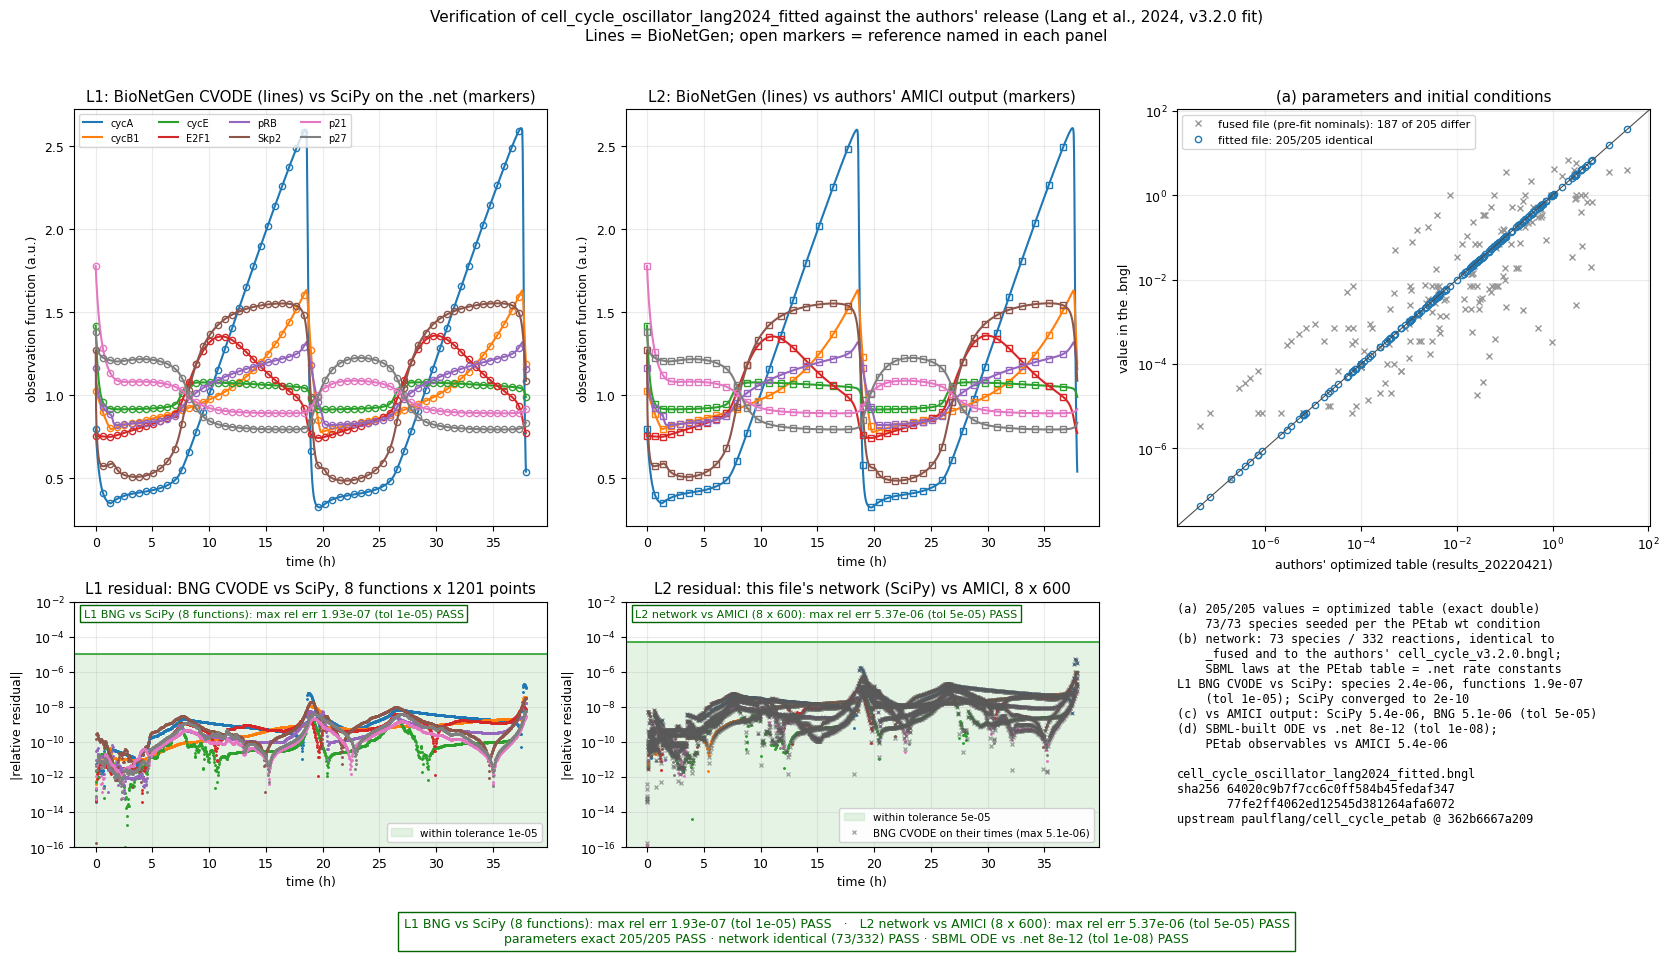

In [9]:
matplotlib.rcParams.update({"font.size": 9})
LAB = {f: f.replace("obs_", "").replace("__nuc_median", "") for f in FN}
col = {f: f"C{i}" for i, f in enumerate(FN)}
h_u, h_a = T_UNIF / 3600, T_AMICI / 3600
fig, ax = plt.subplots(2, 3, figsize=(17, 9.6), gridspec_kw={"height_ratios": [1.7, 1.0]})

a = ax[0, 0]
for f in FN:
    a.plot(h_u, G[:, gh.index(f)], "-", lw=1.5, color=col[f], label=LAB[f])
    a.plot(h_u[::20], F_ref[f][iu][::20], "o", mfc="none", mec=col[f], ms=4.5)
a.set(title="L1: BioNetGen CVODE (lines) vs SciPy on the .net (markers)",
      xlabel="time (h)", ylabel="observation function (a.u.)")
a.legend(fontsize=7, ncol=4, loc="upper left"); a.grid(alpha=0.25)

a = ax[0, 1]
for f in FN:
    a.plot(h_u, G[:, gh.index(f)], "-", lw=1.5, color=col[f], label=LAB[f])
    a.plot(h_a[::15], l2[f][::15], "s", mfc="none", mec=col[f], ms=4.5)
a.set(title="L2: BioNetGen (lines) vs authors' AMICI output (markers)",
      xlabel="time (h)", ylabel="observation function (a.u.)")
a.grid(alpha=0.25)

# Residuals: |relative residual| of every point, log scale, tolerance as a line over a band.
# (A linear axis scaled to the tolerance would flatten residuals of 1e-7 onto zero.)
def log_residual(a, x_by_f, model_by_f, ref_by_f, tol, title, extra=None):
    a.axhspan(1e-17, tol, color="tab:green", alpha=0.12, label=f"within tolerance {tol:g}")
    a.axhline(tol, color="tab:green", lw=1.2)
    for f in FN:
        e = rel_err(model_by_f[f], ref_by_f[f])
        a.semilogy(x_by_f, np.maximum(e, 1e-16), ".", ms=2.2, color=col[f])
    if extra is not None:
        lab, mod = extra
        e = np.concatenate([rel_err(mod[f], ref_by_f[f]) for f in FN])
        a.semilogy(np.concatenate([x_by_f] * len(FN)), np.maximum(e, 1e-16), "x", ms=2.5,
                   color="0.35", alpha=0.5, label=lab)
    a.set(ylim=(1e-16, 1e-2), xlabel="time (h)", ylabel="|relative residual|", title=title)
    a.grid(alpha=0.25, which="major")
    a.legend(fontsize=7.5, loc="lower right", framealpha=0.9)


x1 = np.concatenate([h_u] * len(FN))
m1 = np.concatenate([G[:, gh.index(f)] for f in FN])
r1 = np.concatenate([F_ref[f][iu] for f in FN])
c1 = Comparison("L1 BNG vs SciPy (8 functions)", r1, tol=TOL_BNG, floor=FLOOR)
x2 = np.concatenate([h_a] * len(FN))
m2 = np.concatenate([F_ref[f][ia] for f in FN])
r2 = np.concatenate([l2[f] for f in FN])
c2 = Comparison("L2 network vs AMICI (8 x 600)", r2, tol=TOL_AMICI, floor=FLOOR)
metrics = [summarize(x1, m1, c1), summarize(x2, m2, c2)]
log_residual(ax[1, 0], h_u, {f: G[:, gh.index(f)] for f in FN}, {f: F_ref[f][iu] for f in FN},
             TOL_BNG, "L1 residual: BNG CVODE vs SciPy, 8 functions x 1201 points")
log_residual(ax[1, 1], h_a, {f: F_ref[f][ia] for f in FN}, l2, TOL_AMICI,
             "L2 residual: this file's network (SciPy) vs AMICI, 8 x 600",
             extra=None if l2_bng is None else (f"BNG CVODE on their times (max {l2_bng:.1e})", G_st))
for a, m in ((ax[1, 0], metrics[0]), (ax[1, 1], metrics[1])):
    a.text(0.02, 0.97, m.line(), transform=a.transAxes, fontsize=8, va="top",
           color="darkgreen" if m.passed else "darkred",
           bbox={"fc": "white", "ec": "darkgreen" if m.passed else "darkred", "pad": 2.5})

# Parameter parity: this file vs the optimized table; _fused shown for contrast
a = ax[0, 2]
tv = np.array([float(opt.loc[k, "nominalValue"]) for k in opt.index])
fv = np.array([fitted_params[k] for k in opt.index])
uv = np.array([fused_params[k] for k in opt.index])
nz = (tv > 0) & (fv > 0)
a.loglog(tv[nz & (uv > 0)], uv[nz & (uv > 0)], "x", color="0.6", ms=4,
         label=f"fused file (pre-fit nominals): {len(changed)} of 205 differ")
a.loglog(tv[nz], fv[nz], "o", mfc="none", mec="tab:blue", ms=4.5,
         label=f"fitted file: {205 - len(mismatch)}/205 identical")
lim = [tv[nz].min() / 3, tv[nz].max() * 3]
a.plot(lim, lim, "-", color="0.3", lw=0.8)
a.set(xlim=lim, ylim=lim, xlabel="authors' optimized table (results_20220421)",
      ylabel="value in the .bngl", title="(a) parameters and initial conditions")
a.legend(fontsize=8, loc="upper left"); a.grid(alpha=0.25)

a = ax[1, 2]; a.axis("off")
lines = [
    "(a) 205/205 values = optimized table (exact double)",
    "    73/73 species seeded per the PEtab wt condition",
    "(b) network: 73 species / 332 reactions, identical to",
    "    _fused and to the authors' cell_cycle_v3.2.0.bngl;",
    "    SBML laws at the PEtab table = .net rate constants",
    f"L1 BNG CVODE vs SciPy: species {l1_species:.1e}, functions {l1_funcs:.1e}",
    f"    (tol {TOL_BNG:g}); SciPy converged to {solver_err:.0e}",
    f"(c) vs AMICI output: SciPy {l2_scipy:.1e}" + (f", BNG {l2_bng:.1e}" if l2_bng else "")
    + f" (tol {TOL_AMICI:g})",
    f"(d) SBML-built ODE vs .net {sbml_vs_net:.0e} (tol {TOL_SBML:g});",
    f"    PEtab observables vs AMICI {d_amici:.1e}",
    "",
    f"{STEM}.bngl",
    f"sha256 {FITTED_SHA[:32]}",
    f"       {FITTED_SHA[32:]}",
    f"upstream paulflang/cell_cycle_petab @ {gen.UPSTREAM_COMMIT[:12]}",
]
a.text(0.0, 1.0, "\n".join(lines), va="top", ha="left", family="monospace", fontsize=8.6)

fig.suptitle("Verification of cell_cycle_oscillator_lang2024_fitted against the authors' release "
             "(Lang et al., 2024, v3.2.0 fit)\nLines = BioNetGen; open markers = reference named "
             "in each panel", fontsize=11)
fig.tight_layout(rect=(0, 0.05, 1, 0.96))
ok = verdict_footer(fig, metrics, extra=(
    "parameters exact 205/205 PASS · network identical (73/332) PASS · "
    f"SBML ODE vs .net {sbml_vs_net:.0e} (tol {TOL_SBML:g}) PASS"))
assert ok
fig.savefig("verify_lang2024_fitted.png", dpi=150, bbox_inches="tight")
print("saved verify_lang2024_fitted.png")
plt.show()

## Result

Every assertion above passed:

* **(a)** The `_fitted` file carries the authors' fitted table exactly, and the initial
  state is the PEtab `wt` condition.
* **(b)** Its network is the authors' network.
* **L1** BioNetGen's CVODE agrees with an independent integration of that network.
* **(c)** Integrated from the file, the network reproduces the authors' own simulation of
  the fitted model at all 600 time points of their output. Where `run_network` could launch,
  BioNetGen's own CVODE on the authors' sample times does too.
* **(d)** An ODE built directly from the authors' SBML and PEtab tables, with no BioNetGen
  involved, agrees with the network to roundoff. With its own PEtab observation formulas, it
  agrees with the authors' output.